In [5]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Sample BBO of the oral microbial communities

In [6]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, BlackBoxOptim, Distances, Printf

In [7]:
Plots.theme(:dao)

In [8]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [9]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [10]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

In [11]:
gd1[2]

Row,otu_id,count,project_id,sample_id,run_id,nreads,classification
,Int64,Float64,String15,String15,String15,Float64,String
1,968675,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
2,932696,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
3,1098340,3.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
4,1111525,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
5,905769,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
6,1505940,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
7,1083194,2.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
8,4471251,1.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL
9,865469,3.0,SRP056641,SRS893257,SRR2175795,29.0,ORAL


For each classification, split up on the sample.

In [12]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

Now, we only want to work with a simple system to start. `Oral` at index 2 is a good system that nicely follows Heaps' law.

In [13]:
gd_classes[2];

In [14]:
data = gd_classes[2];

We need to get the size of each of these systems.

In [15]:
# first split on classification (microbiome type)
gd_test = groupby(read_data, :classification);
# for the group of interest (given by data_ind) split up the samples
data_test = groupby(gd_test[2], :sample_id);

In [16]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

130072.0

Let's choose the smallest of these systems as the initial condition.

In [17]:
argmin(sizes)

59

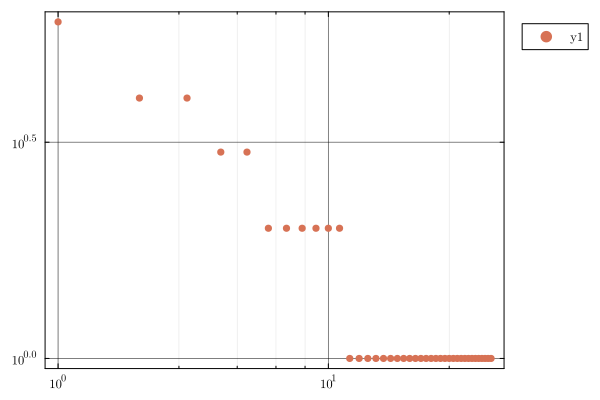

In [18]:
ic_sys = data[argmin(sizes)]
ic_sys = sort(ic_sys[!,:count],rev=true)
scatter(ic_sys, xaxis = :log, yaxis = :log)

Let's import the calibration results.

In [19]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results/eco-calib-2.csv", DataFrame)

Row,p0,theta,gamma,fitness
,Float64,Float64,Float64,Float64
1,141.463,0.770029,1.12188,4.50878
2,47.5745,0.281535,1.03123,5.08507
3,131.847,0.670579,1.11777,3.63662
4,47.5025,0.236704,1.03502,6.19147
5,160.684,0.76732,1.15792,5.1161
6,122.729,0.670941,1.07942,5.12009
7,58.2301,0.339276,1.0169,4.82046
8,166.502,0.762004,1.13807,4.09924
9,89.094,0.646109,1.07223,3.99209


In [20]:
calib_results[1,1]

141.46291233790586

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [21]:
guess_sim = dsim.create_cell(calib_results[1,2],calib_results[1,3],calib_results[1,1],convert(Int64,maximum(sizes)), ic_sys, :pdf)

2088-element Vector{Float64}:
 11264.0
  5740.0
  4819.0
  3698.0
  3451.0
  3423.0
  2702.0
  2304.0
  1923.0
  1652.0
  1572.0
  1420.0
  1359.0
     ⋮
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0
     1.0

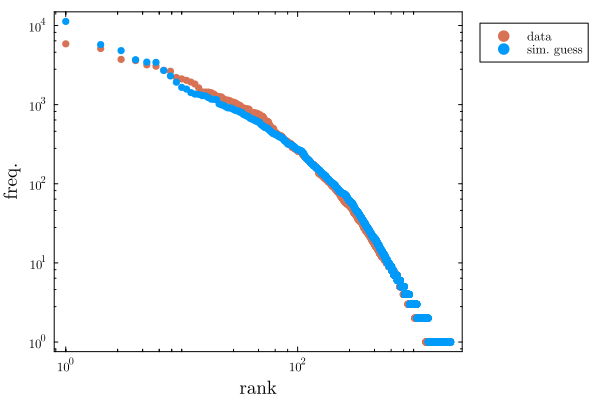

In [22]:
scatter(sort(data[argmax(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data")
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

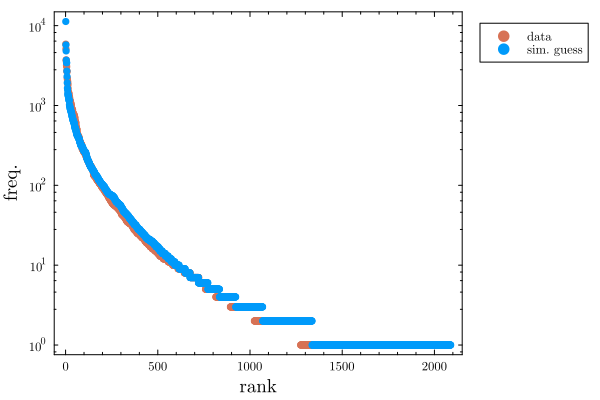

In [23]:
scatter(sort(data[argmax(sizes)][!,:count],rev=true), label = "data", yaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

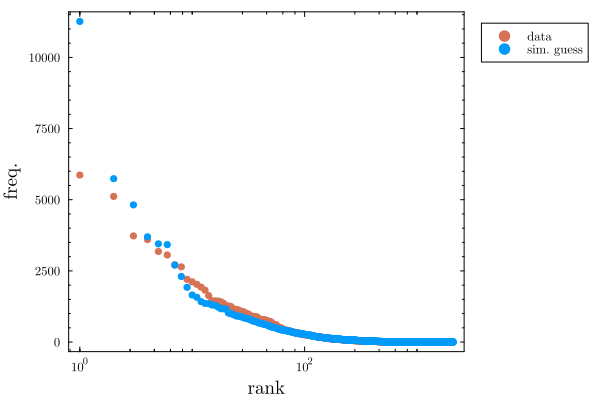

In [24]:
scatter(sort(data[argmax(sizes)][!,:count],rev=true), label = "data", xaxis = :log)
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

Great results. Pretty quickly, we can get something that is bang on!

In [32]:
logxs = log10.(sum.([x[!,:count] for x in data]))
logys = log10.(length.([x[!,:count] for x in data]));

In [33]:
df = DataFrame(y = logys, x = logxs);

In [34]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  0.708404   0.0473157  14.97    <1e-25   0.614417   0.802391
x            0.53238    0.0111613  47.70    <1e-65   0.51021    0.554551
────────────────────────────────────────────────────────────────────────

In [35]:
a,b = coef(glm)

2-element Vector{Float64}:
 0.7084042943965811
 0.532380399267376

Following the SI of the PNAS paper...

In [36]:
θ = 2+1/(b-1);

In [37]:
ic_sys;

In [38]:
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)))
p0_guess = α*a*b

2.129260609129652